Note: you may need to restart the kernel to use updated packages.
Attention权重矩阵 shape: torch.Size([1, 5, 5])


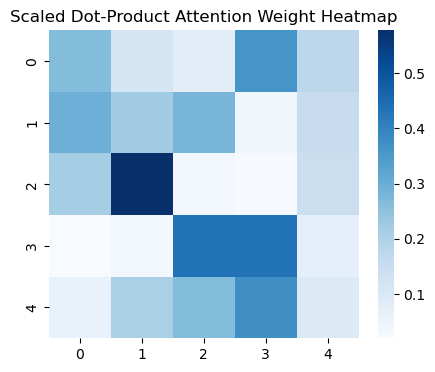

多头注意力输出shape torch.Size([1, 5, 128])


In [1]:

%pip install seaborn
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
    if mask is not None:
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
    attn_weights = torch.softmax(attn_scores, dim=-1)
    output = torch.matmul(attn_weights, V)
    return output, attn_weights

batch_size = 1
seq_len = 5
d_k = 64
Q = torch.randn(batch_size, seq_len, d_k)
K = torch.randn(batch_size, seq_len, d_k)
V = torch.randn(batch_size, seq_len, d_k)

out, attn_w = scaled_dot_product_attention(Q,K,V)
print("Attention权重矩阵 shape:", attn_w.shape)

plt.figure(figsize=(5,4))
sns.heatmap(attn_w[0].detach().numpy(), annot=False, cmap="Blues")
plt.title("Scaled Dot-Product Attention Weight Heatmap")
plt.show()

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
    
    def split_heads(self, x):
        b, s, d = x.shape
        return x.view(b, s, self.num_heads, self.d_k).transpose(1,2) # [batch, head, seq_len, dk]
    
    def forward(self, q, k, v, mask=None):
        b = q.size(0)
        q = self.split_heads(self.w_q(q))
        k = self.split_heads(self.w_k(k))
        v = self.split_heads(self.w_v(v))
        
        attn_out, attn_w = scaled_dot_product_attention(q,k,v,mask)
        attn_out = attn_out.transpose(1,2).contiguous().view(b, -1, self.d_model)
        return self.w_o(attn_out), attn_w

mha = MultiHeadAttention(d_model=128, num_heads=8)
x = torch.randn(1, 5, 128)
mha_out, mha_attn = mha(x,x,x)
print("多头注意力输出shape", mha_out.shape)